# Kaggle Store Sales: CatBoost vs MLP vs Sequential Forecasting Models

**Seventh experiment for the time-series forecasting benchmark.** We predict **16 consecutive days of daily sales** for each `(store_nbr, family)` series in the Kaggle [Store Sales – Time Series Forecasting](https://www.kaggle.com/competitions/store-sales-time-series-forecasting) dataset, comparing:

- **CatBoost (raw lags)** and **CatBoost (engineered)** — global multi-output regressors
- **MLP, GRU, LSTM, causal TCN, patch-based Transformer** — global neural multi-output regressors
- **N-BEATS-style (generic)** and **N-BEATS-style (interpretable)** — simplified research-inspired implementations, **not** canonical N-BEATS reproductions
- **Seasonal naive** — copy last week's sales forward

**Metric:** Kaggle's **RMSLE** (smaller is better), computed over the identical historical 16-day test window. All models predict `log1p(sales)` and are scored after transformation back to nonnegative sales. A validation window is used for early stopping; the **test window is scored only after models have been fit/selected**.

**This is an offline backtest, not a Kaggle leaderboard score.** The original competition's unlabeled August 16–31, 2017 test set cannot be used to compute local RMSLE. We instead use **July 15–30, 2017 for validation**, and **July 31–August 15, 2017 for testing**. Training forecast targets end **on or before July 14**.

**Feature boundary:** all methods use (1) past observed sales and past promotions, (2) *known future* promotions and calendar variables for the 16 forecast days, and (3) store/product-family identity. The `engineered` CatBoost adds causal rolling statistics from historical windows; the neural models receive the **same historical statistics** through their heads. Future sales, future transactions, and future oil-price observations are **not** used. We include a simple national-holiday indicator derived from the provided event calendar. 

This is deliberately an exploratory, single-seed, single-block benchmark. For stronger evidence, run several rolling-origin splits/seeds and tune each architecture on validation; do not generalize a leaderboard from one run.

**Data scope:** for manageable training time this version retains records from January 2016 onward and uses weekly training forecast origins from July 2016 through June 2017, rather than training on the entire 2013–2017 history. All eligible store/product series are included by default. Report this time range when publishing results.

**Data citation:** Alexis Cook, DanB, inversion, and Ryan Holbrook, [Store Sales – Time Series Forecasting](https://www.kaggle.com/competitions/store-sales-time-series-forecasting), Kaggle (2021). Data subject to competition rules.

## 1 · Install and download data

Accept the competition rules while logged into Kaggle, then either download **all CSVs** from the [competition data page](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data), or use the official CLI. Run once in a terminal:

```bash
python -m pip install -U numpy pandas matplotlib scikit-learn torch catboost kaggle
kaggle competitions download -c store-sales-time-series-forecasting -p data/store_sales
unzip -o data/store_sales/store-sales-time-series-forecasting.zip -d data/store_sales
```

Kaggle CLI authentication requires an authorized local Kaggle configuration; do **not** put API tokens into this notebook or upload them to GitHub. On Kaggle Notebooks, attach the competition data and use `/kaggle/input/store-sales-time-series-forecasting`.

Minimum input files: **`train.csv` and `holidays_events.csv`** (holidays optional; other competition files are not necessary for this fair input-feature comparison). The notebook searches common folders automatically. Set `DATA_DIR` manually if needed.

In [1]:
# Uncomment once if packages are missing, then restart the kernel.
# %pip install -U numpy pandas matplotlib torch catboost
from pathlib import Path
import os, json, time, random, copy, math, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display
from catboost import CatBoostRegressor

# Point this at the folder containing train.csv if autodetection does not work.
DATA_DIR = None
OUTPUT_DIR = Path('forecast_challenge_outputs/store_sales')
SEED = 42
CONTEXT = 64
HORIZON = 16
TRAIN_ORIGINS_START = '2016-07-01'
TRAIN_ORIGINS_END = '2017-06-29'
VALID_START = '2017-07-15'
TEST_START = '2017-07-31'
TRAIN_ORIGIN_STEP_DAYS = 7     # 7 = moderate CPU-friendly benchmark; 2 = larger training budget
N_SERIES = None              # None = all eligible store/family series
MAX_EPOCHS = 14
PATIENCE = 4
BATCH_SIZE = 512
CATBOOST_ITERATIONS = 400
CATBOOST_PATIENCE = 45
NEURAL_LR = 1e-3
SMOKE_TEST = False            # True: code check only! Results must NOT be used in the article.

if SMOKE_TEST:
    N_SERIES = 24
    TRAIN_ORIGIN_STEP_DAYS = 28
    MAX_EPOCHS = 2
    CATBOOST_ITERATIONS = 15
    CATBOOST_PATIENCE = 5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(os.cpu_count() or 1, 4))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu'))
print('Device:', DEVICE, '| PyTorch:', torch.__version__, '| CPU:', platform.processor())
print('Mode:', 'SMOKE TEST / NOT FOR ARTICLE' if SMOKE_TEST else 'STANDARD / REAL-DATA EXPERIMENT')

candidates = [Path(DATA_DIR).expanduser()] if DATA_DIR else [
    Path('data/store_sales'), Path('data/store-sales-time-series-forecasting'),
    Path('store-sales-time-series-forecasting'), Path('/kaggle/input/store-sales-time-series-forecasting'),
    Path('.'), Path('../data/store_sales'), Path('Time_Series_Benchmark_Final/data/store_sales'),
]
found = [p for p in candidates if (p / 'train.csv').is_file()]
if not found:
    raise FileNotFoundError('Cannot find train.csv. Download and extract the Kaggle competition data, then set DATA_DIR to its folder. Checked: '+', '.join(map(str,candidates)))
DATA_DIR = found[0]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Reading competition data from', DATA_DIR.resolve())
print('Saving results to', OUTPUT_DIR.resolve())

Device: mps | PyTorch: 2.12.0 | CPU: arm
Mode: STANDARD / REAL-DATA EXPERIMENT
Reading competition data from /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/data/store_sales
Saving results to /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/store_sales


## 2 · Prepare series and known-in-advance covariates

All 54 stores × 33 product families are eligible if the chosen validation and test targets have complete observations. Missing *historical* rows are filled with zero; this is a pragmatic choice and can affect stores that opened late. The notebook reports the number of retained series and does not silently evaluate targets that were missing from the original CSV.

In [2]:
usecols=['date','store_nbr','family','sales','onpromotion']
df=pd.read_csv(DATA_DIR/'train.csv',usecols=usecols,parse_dates=['date'],dtype={'store_nbr':'int16','family':'category','sales':'float32','onpromotion':'float32'})
df=df.loc[df.date>=pd.Timestamp('2016-01-01')].copy()
df['sales']=df['sales'].clip(lower=0)
df['onpromotion']=df['onpromotion'].fillna(0).clip(lower=0)
dates=pd.date_range(df.date.min(),df.date.max(),freq='D',name='date')

# Stable matrix columns: one column for each store × family.
stores=sorted(df.store_nbr.unique().tolist())
families=sorted(map(str,df.family.cat.categories))
columns=pd.MultiIndex.from_product([stores,families],names=['store_nbr','family'])
sp=df.pivot(index='date',columns=['store_nbr','family'],values='sales').reindex(index=dates,columns=columns)
pp=df.pivot(index='date',columns=['store_nbr','family'],values='onpromotion').reindex(index=dates,columns=columns)
observed=np.isfinite(sp.to_numpy(dtype='float32'))
sales=np.maximum(np.nan_to_num(sp.to_numpy(dtype='float32'),nan=0),0)
promos=np.maximum(np.nan_to_num(pp.to_numpy(dtype='float32'),nan=0),0)
L=np.log1p(sales).astype('float32')
P=np.log1p(promos).astype('float32')
del sp,pp,df

dow=dates.dayofweek.to_numpy()
month=dates.month.to_numpy()
is_weekend=(dow>=5).astype('float32')
is_payday=((dates.day==15)|dates.is_month_end).astype('float32')
holiday_dates=set()
if (DATA_DIR/'holidays_events.csv').is_file():
    he=pd.read_csv(DATA_DIR/'holidays_events.csv',parse_dates=['date'])
    t=he['transferred'].fillna(False).astype(str).str.lower().eq('true') if 'transferred' in he else pd.Series(False,index=he.index)
    valid=(he['locale'].eq('National') & ~t & ~he['type'].eq('Work Day'))
    holiday_dates=set(he.loc[valid,'date'].dt.normalize())
    print('Using known national-holiday calendar. Rows:',int(valid.sum()))
else:
    print('holidays_events.csv not found: national-holiday feature will be all zeros')
cal=np.stack([
    np.sin(2*np.pi*dow/7),np.cos(2*np.pi*dow/7),
    np.sin(2*np.pi*(month-1)/12),np.cos(2*np.pi*(month-1)/12),
    is_weekend,is_payday,np.array([float(dt in holiday_dates) for dt in dates],dtype='float32')
],axis=1).astype('float32')
CAL_NAMES=['dow_sin','dow_cos','month_sin','month_cos','weekend','payday','national_holiday']
FUTURE_NAMES=['future_log_promo']+CAL_NAMES

def date_idx(text):
    dt=pd.Timestamp(text)
    match=np.where(dates==dt)[0]
    if len(match)!=1: raise ValueError('Required date missing from daily grid: '+text)
    return int(match[0])
val_i=date_idx(VALID_START);test_i=date_idx(TEST_START)
assert test_i==val_i+HORIZON, 'Validation and test windows should not overlap or have a gap.'
assert test_i+HORIZON<=len(dates)

# Only evaluate store/family series with all 32 validation/test target observations.
eligible=np.where(observed[val_i:val_i+HORIZON].all(axis=0)&observed[test_i:test_i+HORIZON].all(axis=0))[0]
if N_SERIES is not None:
    rng=np.random.default_rng(SEED)
    eligible=np.sort(rng.choice(eligible,size=min(int(N_SERIES),len(eligible)),replace=False))
if not len(eligible): raise RuntimeError('No series have complete targets in validation and test!')
L=L[:,eligible];P=P[:,eligible];observed=observed[:,eligible]
chosen=[columns[i] for i in eligible]
store_values=np.array([int(c[0]) for c in chosen],dtype=np.int64)
family_values=np.array([families.index(c[1]) for c in chosen],dtype=np.int64)
store_ix=np.array([stores.index(i) for i in store_values],dtype=np.int64)
family_ix=family_values
nseries=len(eligible)

train_dates=pd.date_range(TRAIN_ORIGINS_START,TRAIN_ORIGINS_END,freq=f'{TRAIN_ORIGIN_STEP_DAYS}D')
train_origins=np.array([date_idx(str(x.date())) for x in train_dates],dtype=np.int32)
train_origins=train_origins[(train_origins>=CONTEXT)&(train_origins+HORIZON<=val_i)]
if not len(train_origins): raise RuntimeError('No eligible training forecast origins')
train_pairs=np.array([(o,s) for o in train_origins for s in range(nseries) if observed[o:o+HORIZON,s].all()],dtype=np.int32)
val_pairs=np.column_stack((np.full(nseries,val_i,dtype=np.int32),np.arange(nseries,dtype=np.int32)))
test_pairs=np.column_stack((np.full(nseries,test_i,dtype=np.int32),np.arange(nseries,dtype=np.int32)))
print('Dates:',dates[0].date(),'to',dates[-1].date())
print('Series retained:',nseries,'of',len(columns))
print('Train origins:',len(train_origins),'| training windows:',len(train_pairs))
print('Validation:',VALID_START,'through',dates[val_i+HORIZON-1].date())
print('Test:',TEST_START,'through',dates[test_i+HORIZON-1].date())
assert len(train_pairs)>0

Using known national-holiday calendar. Rows: 161
Dates: 2016-01-01 to 2017-08-15
Series retained: 1782 of 1782
Train origins: 52 | training windows: 89100
Validation: 2017-07-15 through 2017-07-30
Test: 2017-07-31 through 2017-08-15


## 3 · Build identical forecast windows

Training is **direct multi-horizon forecasting**: the networks output 16 predictions at once and CatBoost uses `MultiRMSE` on the same 16 log-transformed targets. There is no recursive exposure to predicted values and no future measured target within the input. Model selection uses validation RMSLE only.

In [3]:
lag_offsets=np.arange(-CONTEXT,0,dtype=np.int32)
forecast_offsets=np.arange(HORIZON,dtype=np.int32)

def engineer(hist):
    """Statistics from each sample's observed past only; shape (B, 9)."""
    y=hist[:,:,0]; promo=hist[:,:,1]
    return np.column_stack([
        y[:,-1],y[:,-7:].mean(axis=1),y[:,-28:].mean(axis=1),
        y[:,-7:].std(axis=1),y[:,-28:].std(axis=1),
        y[:,-7::7].mean(axis=1),y[:,-1]-y[:,-8],
        promo[:,-7:].mean(axis=1),promo[:,-28:].mean(axis=1)
    ]).astype('float32')
STATS_NAMES=['last_log_sales','mean_7','mean_28','std_7','std_28','same_weekday_mean','delta_7','promo_mean_7','promo_mean_28']

def batch_np(pairs):
    o=pairs[:,0];s=pairs[:,1]
    hi=o[:,None]+lag_offsets[None,:];fi=o[:,None]+forecast_offsets[None,:]
    h=np.stack([L[hi,s[:,None]],P[hi,s[:,None]]],axis=-1).astype('float32')
    fut=np.concatenate([P[fi,s[:,None],None],cal[fi]],axis=2).astype('float32')
    yy=L[fi,s[:,None]].astype('float32')
    stats=engineer(h)
    return dict(history=h,future=fut,stats=stats,store=store_ix[s],family=family_ix[s],target=yy)

class PairDataset(Dataset):
    def __init__(self,pairs): self.pairs=pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self,i): return self.pairs[i]

def collate_pairs(rows):
    d=batch_np(np.asarray(rows,dtype=np.int32))
    return {k:torch.from_numpy(np.asarray(v)).float() if k not in ('store','family') else torch.from_numpy(np.asarray(v)).long() for k,v in d.items()}

train_loader=DataLoader(PairDataset(train_pairs),batch_size=BATCH_SIZE,shuffle=True,collate_fn=collate_pairs,num_workers=0)
val_loader=DataLoader(PairDataset(val_pairs),batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_pairs,num_workers=0)
test_loader=DataLoader(PairDataset(test_pairs),batch_size=BATCH_SIZE,shuffle=False,collate_fn=collate_pairs,num_workers=0)

sample=batch_np(val_pairs[:3])
print({k:v.shape for k,v in sample.items()})
assert sample['history'].shape==(3,CONTEXT,2)
assert sample['future'].shape==(3,HORIZON,1+len(CAL_NAMES))
assert sample['target'].shape==(3,HORIZON)

{'history': (3, 64, 2), 'future': (3, 16, 8), 'stats': (3, 9), 'store': (3,), 'family': (3,), 'target': (3, 16)}


## 4 · Baseline and neural architectures

The models below are **compact, reasonably matched implementations**, not official model-library reproductions. The N-BEATS variants implement a residual backcast/forecast decomposition with generic learned or interpretable trend/seasonal bases. The Transformer is a **patch-based encoder**, not an official PatchTST reproduction. All neural heads can use the same known-future features and historical engineered statistics.

In [4]:
FUT_DIM=1+len(CAL_NAMES)
STATS_DIM=len(STATS_NAMES)

class StaticHead(nn.Module):
    def __init__(self,backbone_dim,hidden=128):
        super().__init__()
        self.store_embedding=nn.Embedding(len(stores),12)
        self.family_embedding=nn.Embedding(len(families),12)
        d=backbone_dim+HORIZON*FUT_DIM+STATS_DIM+24
        self.head=nn.Sequential(nn.Linear(d,hidden),nn.ReLU(),nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,HORIZON))
    def forward(self,z,fx,stats,store,family):
        cat=torch.cat([z,fx.flatten(1),stats,self.store_embedding(store),self.family_embedding(family)],dim=1)
        return self.head(cat)

class MLPForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Flatten(),nn.Linear(CONTEXT*2,128),nn.ReLU(),nn.Linear(128,64),nn.ReLU())
        self.out=StaticHead(64)
    def forward(self,history,future,stats,store,family):
        return self.out(self.encoder(history),future,stats,store,family)

class RNNForecast(nn.Module):
    def __init__(self,kind='GRU'):
        super().__init__()
        rnn=nn.GRU if kind=='GRU' else nn.LSTM
        self.rnn=rnn(input_size=2,hidden_size=64,num_layers=1,batch_first=True)
        self.out=StaticHead(64)
    def forward(self,history,future,stats,store,family):
        _,hidden=self.rnn(history)
        if isinstance(hidden,tuple): hidden=hidden[0]
        return self.out(hidden[-1],future,stats,store,family)

class CausalConv1d(nn.Module):
    def __init__(self,cin,cout,k,dilation):
        super().__init__()
        self.crop=(k-1)*dilation
        self.conv=nn.Conv1d(cin,cout,k,padding=self.crop,dilation=dilation)
    def forward(self,x):
        y=self.conv(x)
        return y[:,:,:-self.crop] if self.crop else y

class TCNForecast(nn.Module):
    def __init__(self):
        super().__init__()
        layers=[];dim=2
        for d in [1,2,4,8,16,32]:
            layers += [CausalConv1d(dim,32,3,d),nn.ReLU()]
            dim=32
        self.network=nn.Sequential(*layers)
        self.out=StaticHead(32)
    def forward(self,history,future,stats,store,family):
        z=self.network(history.transpose(1,2))[:,:,-1]
        return self.out(z,future,stats,store,family)

class PatchTransformerForecast(nn.Module):
    def __init__(self,patch=8,width=64):
        super().__init__()
        assert CONTEXT%patch==0
        self.patch=patch
        self.proj=nn.Linear(patch*2,width)
        self.pos=nn.Parameter(torch.randn(1,CONTEXT//patch,width)*0.02)
        layer=nn.TransformerEncoderLayer(d_model=width,nhead=4,dim_feedforward=128,batch_first=True,dropout=0.1)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.out=StaticHead(width)
    def forward(self,history,future,stats,store,family):
        x=history.reshape(history.shape[0],CONTEXT//self.patch,self.patch*2)
        h=self.encoder(self.proj(x)+self.pos).mean(dim=1)
        return self.out(h,future,stats,store,family)

class NBeatsBlock(nn.Module):
    def __init__(self,mode):
        super().__init__()
        self.mode=mode
        self.net=nn.Sequential(nn.Linear(CONTEXT,96),nn.ReLU(),nn.Linear(96,96),nn.ReLU())
        if mode=='generic':
            self.b=nn.Linear(96,CONTEXT);self.f=nn.Linear(96,HORIZON)
        else:
            basis_n=7 if mode=='trend' else 8
            self.b=nn.Linear(96,basis_n);self.f=nn.Linear(96,basis_n)
            t_hist=torch.linspace(-1,0,CONTEXT)
            t_fut=torch.linspace(0,1,HORIZON)
            def bases(t):
                if mode=='trend': return torch.stack([t**i for i in range(7)],dim=0)
                return torch.stack([v for k in range(1,5) for v in (torch.cos(2*torch.pi*k*t),torch.sin(2*torch.pi*k*t))],dim=0)
            self.register_buffer('basis_hist',bases(t_hist))
            self.register_buffer('basis_future',bases(t_fut))
    def forward(self,x):
        z=self.net(x)
        b=self.b(z);f=self.f(z)
        if self.mode!='generic':
            b=b @ self.basis_hist
            f=f @ self.basis_future
        return b,f

class NBeatsStyleForecast(nn.Module):
    def __init__(self,kind='generic'):
        super().__init__()
        modes=['generic','generic','generic'] if kind=='generic' else ['trend','seasonality','trend','seasonality']
        self.blocks=nn.ModuleList(NBeatsBlock(x) for x in modes)
        self.context=StaticHead(32)
        self.context_proj=nn.Sequential(nn.Linear(CONTEXT*2,32),nn.ReLU())
    def forward(self,history,future,stats,store,family):
        residual=history[:,:,0]
        forecast=torch.zeros(history.shape[0],HORIZON,device=history.device)
        for block in self.blocks:
            back,front=block(residual)
            residual=residual-back
            forecast=forecast+front
        residual_head=self.context(self.context_proj(history.flatten(1)),future,stats,store,family)
        return forecast+residual_head

NEURAL_MODELS={
    'MLP': MLPForecast,
    'GRU': lambda:RNNForecast('GRU'),
    'LSTM': lambda:RNNForecast('LSTM'),
    'TCN': TCNForecast,
    'Patch Transformer': PatchTransformerForecast,
    'N-BEATS-style (generic)':lambda:NBeatsStyleForecast('generic'),
    'N-BEATS-style (interpretable)':lambda:NBeatsStyleForecast('interpretable'),
}
print('Neural models:',', '.join(NEURAL_MODELS))

Neural models: MLP, GRU, LSTM, TCN, Patch Transformer, N-BEATS-style (generic), N-BEATS-style (interpretable)


## 5 · Train neural models (validation-only early stopping)

**Budget:** each neural model receives the same maximum epoch count and stopping patience. Epochs and training times are reported. These are not equal-parameter-count or equal-compute benchmarks; differences in optimization difficulty and compute budgets remain important limitations.

In [5]:
def rmsle_log(y,p):
    # log1p(sales) squared loss is equivalent to RMSLE for nonnegative predictions.
    return float(np.sqrt(np.mean((np.maximum(p,0)-y)**2)))

def neural_predict(model,loader):
    model.eval();pieces=[];labels=[]
    with torch.no_grad():
        for b in loader:
            x={k:v.to(DEVICE) for k,v in b.items()}
            prediction=model(x['history'],x['future'],x['stats'],x['store'],x['family'])
            pieces.append(prediction.cpu().numpy());labels.append(x['target'].cpu().numpy())
    return np.concatenate(labels),np.concatenate(pieces)

def fit_neural(name,builder):
    torch.manual_seed(SEED)
    model=builder().to(DEVICE)
    optim=torch.optim.Adam(model.parameters(),lr=NEURAL_LR)
    best=np.inf;bad=0;best_epoch=0;best_state=None;t0=time.perf_counter()
    for ep in range(1,MAX_EPOCHS+1):
        model.train();runloss=[]
        for b in train_loader:
            x={k:v.to(DEVICE) for k,v in b.items()}
            optim.zero_grad(set_to_none=True)
            prediction=model(x['history'],x['future'],x['stats'],x['store'],x['family'])
            loss=(prediction-x['target']).square().mean()
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optim.step()
            runloss.append(float(loss.detach().cpu()))
        y_val,p_val=neural_predict(model,val_loader)
        score=rmsle_log(y_val,p_val)
        print(f'{name:31s} epoch {ep:2d} train_log_mse={np.mean(runloss):.5f} val_RMSLE={score:.5f}')
        if score<best-1e-5:
            best=score;best_epoch=ep;best_state=copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()});bad=0
        else:
            bad+=1
        if bad>=PATIENCE:break
    model.load_state_dict(best_state)
    # Evaluate predictions only after final selection from validation.
    return model,dict(val_rmsle=float(best),best_epoch=int(best_epoch),train_seconds=float(time.perf_counter()-t0))

results=[]
predictions={}
for name,make in NEURAL_MODELS.items():
    model,metrics=fit_neural(name,make)
    y,p=neural_predict(model,test_loader)
    predictions[name]=p
    results.append(dict(model=name,family='Neural',**metrics))
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

MLP                             epoch  1 train_log_mse=1.47250 val_RMSLE=0.46356
MLP                             epoch  2 train_log_mse=0.24887 val_RMSLE=0.50641
MLP                             epoch  3 train_log_mse=0.22684 val_RMSLE=0.48295
MLP                             epoch  4 train_log_mse=0.20285 val_RMSLE=0.46161
MLP                             epoch  5 train_log_mse=0.19164 val_RMSLE=0.53000
MLP                             epoch  6 train_log_mse=0.18557 val_RMSLE=0.50124
MLP                             epoch  7 train_log_mse=0.17996 val_RMSLE=0.47182
MLP                             epoch  8 train_log_mse=0.17457 val_RMSLE=0.47590
GRU                             epoch  1 train_log_mse=1.64513 val_RMSLE=0.46562
GRU                             epoch  2 train_log_mse=0.23911 val_RMSLE=0.44896
GRU                             epoch  3 train_log_mse=0.21069 val_RMSLE=0.47109
GRU                             epoch  4 train_log_mse=0.19899 val_RMSLE=0.49935
GRU                         

## 6 · Train CatBoost (same forecast windows and targets)

CatBoost models use **multi-output regression in log1p(sales) space**, so both trees and neural networks forecast the identical 16 future targets. The `engineered` CatBoost receives exactly the nine causal summary features available to neural heads; raw CatBoost does not. Store and family use CatBoost's native categorical-feature handling.

Multi-output CatBoost can require substantial CPU RAM and runtime. If it is too slow, reduce `TRAIN_ORIGIN_STEP_DAYS`'s *density* (e.g., increase from 7 to 14), `CATBOOST_ITERATIONS`, or set `SMOKE_TEST=True` to check code only. Report any budget change in the article.

In [6]:
HISTORY_NAMES=[f'log_sales_lag_{CONTEXT-k}' for k in range(CONTEXT)]+[f'log_promo_lag_{CONTEXT-k}' for k in range(CONTEXT)]
FUTURE_FLAT_NAMES=[f'{nm}_h{h+1}' for h in range(HORIZON) for nm in FUTURE_NAMES]
RAW_COLS=HISTORY_NAMES+FUTURE_FLAT_NAMES+['store_nbr','family']

def as_catboost_frame(pairs,engineered=False,chunk_size=3000):
    pieces=[];ys=[]
    for begin in range(0,len(pairs),chunk_size):
        ppairs=pairs[begin:begin+chunk_size]
        b=batch_np(ppairs)
        hist=b['history']
        xs=np.concatenate([hist[:,:,0],hist[:,:,1],b['future'].reshape(len(ppairs),-1)],axis=1)
        names=HISTORY_NAMES+FUTURE_FLAT_NAMES
        if engineered:
            xs=np.column_stack([xs,b['stats']]);names=names+STATS_NAMES
        frame=pd.DataFrame(xs,columns=names,dtype=np.float32)
        frame['store_nbr']=[str(stores[k]) for k in b['store']]
        frame['family']=[families[k] for k in b['family']]
        pieces.append(frame);ys.append(b['target'])
    return pd.concat(pieces,ignore_index=True),np.concatenate(ys)

Xtr_raw,Ytr=as_catboost_frame(train_pairs,engineered=False)
Xva_raw,Yva=as_catboost_frame(val_pairs,engineered=False)
print('CatBoost raw feature matrix:',Xtr_raw.shape,'| targets:',Ytr.shape)

for label,eng in [('CatBoost (raw lags)',False),('CatBoost (engineered)',True)]:
    if eng:
        # Rebuild in the same feature order for fit and predict (important for categorical columns).
        Xtr,_=as_catboost_frame(train_pairs,engineered=True)
        Xva,_=as_catboost_frame(val_pairs,engineered=True)
    else:
        Xtr=Xtr_raw;Xva=Xva_raw
    cb=CatBoostRegressor(
        loss_function='MultiRMSE',eval_metric='MultiRMSE',
        iterations=CATBOOST_ITERATIONS,learning_rate=0.05,depth=6,
        l2_leaf_reg=3.0,random_seed=SEED,
        thread_count=min(6,os.cpu_count() or 1),
        allow_writing_files=False,verbose=False,
        one_hot_max_size=60)
    tic=time.perf_counter()
    cb.fit(Xtr,Ytr,cat_features=['store_nbr','family'],eval_set=(Xva,Yva),
           early_stopping_rounds=CATBOOST_PATIENCE,verbose=False)
    elapsed=time.perf_counter()-tic
    Xte,Yte=as_catboost_frame(test_pairs,engineered=eng)
    predict=np.asarray(cb.predict(Xte),dtype='float32').reshape(-1,HORIZON)
    predictions[label]=predict
    val_pred=np.asarray(cb.predict(Xva),dtype='float32').reshape(-1,HORIZON)
    info=dict(model=label,family='Tree',best_epoch=int(cb.best_iteration_+1),train_seconds=float(elapsed),val_rmsle=rmsle_log(Yva,val_pred))
    results.append(info)
    print(label,'validation RMSLE',round(info['val_rmsle'],5),'best trees:',info['best_epoch'],'train_seconds:',round(elapsed,1))
    del cb,Xte,Xtr,Xva

CatBoost raw feature matrix: (89100, 258) | targets: (89100, 16)
CatBoost (raw lags) validation RMSLE 0.44871 best trees: 209 train_seconds: 90.8
CatBoost (engineered) validation RMSLE 0.44759 best trees: 267 train_seconds: 113.1


## 7 · Held-out test metrics and export

All predictions are generated from models already selected with validation only. The test scores are **not** for tuning hyperparameters. The seasonal naive baseline repeats historical weekly sales, and receives the same observed history.

Held-out 16-day RMSLE — lower is better


,model,family,val_rmsle,best_epoch,train_seconds,rmsle,mae,smape,n_test_values
0,CatBoost (engineered),Tree,0.4476,267.0,113.1268,0.5106,129.6440,62.9559,28512
1,CatBoost (raw lags),Tree,0.4487,209.0,90.7685,0.5128,125.3287,63.7507,28512
2,Seasonal naive,Naive,0.5212,NaN,0.0000,0.6170,96.5354,43.3415,28512
3,MLP,Neural,0.4616,4.0,7.7404,0.6759,116.0494,66.6702,28512
4,LSTM,Neural,0.4478,2.0,8.5538,0.6829,187.9773,76.1700,28512
5,GRU,Neural,0.4490,2.0,19.1349,0.7179,174.2550,75.0459,28512
6,Patch Transformer,Neural,0.4426,10.0,21.0896,0.8917,221.8848,84.8286,28512
7,N-BEATS-style (generic),Neural,0.4259,4.0,10.4620,1.2526,164.5730,85.3751,28512
8,N-BEATS-style (interpretable),Neural,0.4218,7.0,17.7348,1.5286,219.8609,98.7261,28512
9,TCN,Neural,0.4653,7.0,14.6448,1.9663,226.7337,122.2376,28512


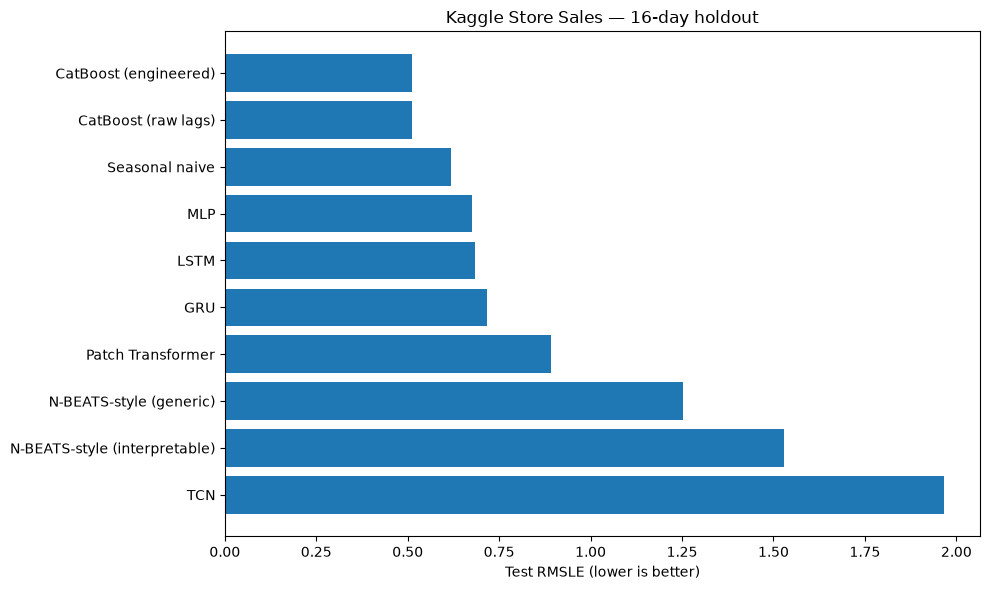

Saved:
  forecast_challenge_outputs/store_sales/comparison.csv
  forecast_challenge_outputs/store_sales/run_info.json
  forecast_challenge_outputs/store_sales/model_comparison.png


In [7]:
y_val=batch_np(val_pairs)['target']
y_test=batch_np(test_pairs)['target']

def seasonal_naive(pairs):
    h=batch_np(pairs)['history'][:,:,0]
    return np.stack([h[:,-7+j%7] for j in range(HORIZON)],axis=1)

naive_val=seasonal_naive(val_pairs)
naive_test=seasonal_naive(test_pairs)
predictions['Seasonal naive']=naive_test
results.append(dict(model='Seasonal naive',family='Naive',best_epoch=np.nan,train_seconds=0.,val_rmsle=rmsle_log(y_val,naive_val)))

rows=[]
for item in results:
    pred=np.asarray(predictions[item['model']],dtype='float64')
    # All forecasts use valid nonnegative sales (equivalent to clipping negative log sales to 0).
    yp=np.maximum(pred,0)
    actual=np.expm1(y_test.astype('float64'))
    forecast=np.expm1(yp)
    rmsle=float(np.sqrt(np.mean((yp-y_test)**2)))
    mae=float(np.mean(np.abs(actual-forecast)))
    smape=float(200*np.mean(np.abs(actual-forecast)/(np.abs(actual)+np.abs(forecast)+1e-8)))
    rows.append(dict(**item,rmsle=rmsle,mae=mae,smape=smape,n_test_values=int(actual.size)))
comparison=pd.DataFrame(rows).sort_values('rmsle').reset_index(drop=True)
assert np.isfinite(comparison['rmsle']).all()
print('Held-out 16-day RMSLE — lower is better')
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR/'comparison.csv',index=False)

metadata={
 'dataset':'Kaggle Favorita Store Sales', 'metric':'RMSLE', 'metric_direction':'lower_is_better',
 'competition_url':'https://www.kaggle.com/competitions/store-sales-time-series-forecasting',
 'context_days':CONTEXT,'horizon_days':HORIZON,
 'train_origins_start':TRAIN_ORIGINS_START,'train_origins_end':TRAIN_ORIGINS_END,
 'train_origin_step_days':TRAIN_ORIGIN_STEP_DAYS,
 'validation_start':VALID_START,'test_start':TEST_START,
 'n_series':nseries,'n_train_windows':int(len(train_pairs)),
 'loaded_history_from':'2016-01-01', 'competition_full_history_used':False,
 'neural_max_epochs':MAX_EPOCHS,'catboost_max_trees':CATBOOST_ITERATIONS,
 'patience_neural':PATIENCE,'patience_catboost':CATBOOST_PATIENCE,
 'smoke_test':bool(SMOKE_TEST),'seed':SEED,
 'device':str(DEVICE),'python':platform.python_version(),
 'notes':'One 16-day validation block and one 16-day test block. Predictions evaluated only against observed targets. No future sales/transactions/oil inputs. Native CatBoost categorical store/family. N-BEATS and patch Transformer are research-inspired, not paper reproductions.'
}
(OUTPUT_DIR/'run_info.json').write_text(json.dumps(metadata,indent=2))

fig,ax=plt.subplots(figsize=(10,6))
d=comparison.sort_values('rmsle',ascending=True)
ax.barh(d['model'].iloc[::-1],d['rmsle'].iloc[::-1])
ax.set_xlabel('Test RMSLE (lower is better)')
ax.set_title('Kaggle Store Sales — 16-day holdout')
plt.tight_layout()
fig.savefig(OUTPUT_DIR/'model_comparison.png',dpi=190,bbox_inches='tight')
plt.show()
print('Saved:')
for name in ['comparison.csv','run_info.json','model_comparison.png']:
    print(' ',OUTPUT_DIR/name)
if SMOKE_TEST:
    print('WARNING: SMOKE_TEST=True; these are intentionally small code-check scores, NOT article results.')

## 8 · How to interpret and report this experiment

1. **Compare RMSLE only within Store Sales.** CO₂, Jena, ETTh1 and Tourism use different error metrics/units. Report percentages relative to Store Sales' MLP or relative to seasonal naive if summarizing multiple datasets.
2. **Be transparent about computational budgets.** In this setup, CatBoost sees `log1p` targets, and neural models learn the same transformed targets. One single seed, one validation block and one test block do not establish that architecture *X* usually wins.
3. **No hidden-test claims.** July 31–Aug 15 is a historical backtest, not the August 16–31 competition test set; no Kaggle leaderboard result is generated.
4. **Feature parity is approximate, not perfect.** All models receive the same raw information and future-known covariates. Neural networks get embeddings for store/family and causal summary stats. CatBoost gets native categorical handling; engineered CatBoost gets matching summary stats. Architecture-specific processing and CatBoost's categorical statistics remain different.
5. **N-BEATS/Transformer naming:** these are compact *-style* implementations. For claims about official N-BEATS, N-HiTS or PatchTST, use those reference implementations and matched tuning budgets.

### When you're done

Save the **executed `.ipynb`** and upload it alongside:

- `forecast_challenge_outputs/store_sales/comparison.csv`
- `forecast_challenge_outputs/store_sales/run_info.json`
- `forecast_challenge_outputs/store_sales/model_comparison.png`

Then the Store Sales results can be included as the next dataset in the Medium article. Cite this Kaggle dataset subject to the competition's terms and **do not upload Kaggle data or API credentials to GitHub**.